# 02 — Exploratory Analysis

**Objective:** establish the business baseline: how many orders/customers,
how much revenue, how concentrated the customer base is.

**Business questions:** What does a typical Olist order look like? How many
customers ever come back? Where does revenue come from?

In [1]:
import sys
from pathlib import Path

# Make the repo's src/ package importable when running from notebooks/.
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import data_loading as dl
from src.config import get_engine
from src.visualization import PALETTE, set_style

set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
engine = get_engine()


## Headline KPIs (qualifying = delivered orders)

In [2]:
kpi = dl.load_table("analytics.kpi_overview", engine)
kpi.T.rename(columns={0: "value"})

,value
total_orders,99441
delivered_orders,96478
canceled_orders,625
unavailable_orders,609
in_progress_orders,1729
total_customers,96096
customers_with_delivered_order,93358
total_revenue_brl,"15,419,773.75"
avg_order_value_brl,159.83
first_order_date,2016-09-04


**Reading the numbers:** ~96.5% of orders reach 'delivered' status.
Revenue is defined as item price + freight summed over delivered orders
(payments are kept as a separate reconciliation measure because ~250
orders show payment/item mismatches).

## Monthly orders & revenue trend

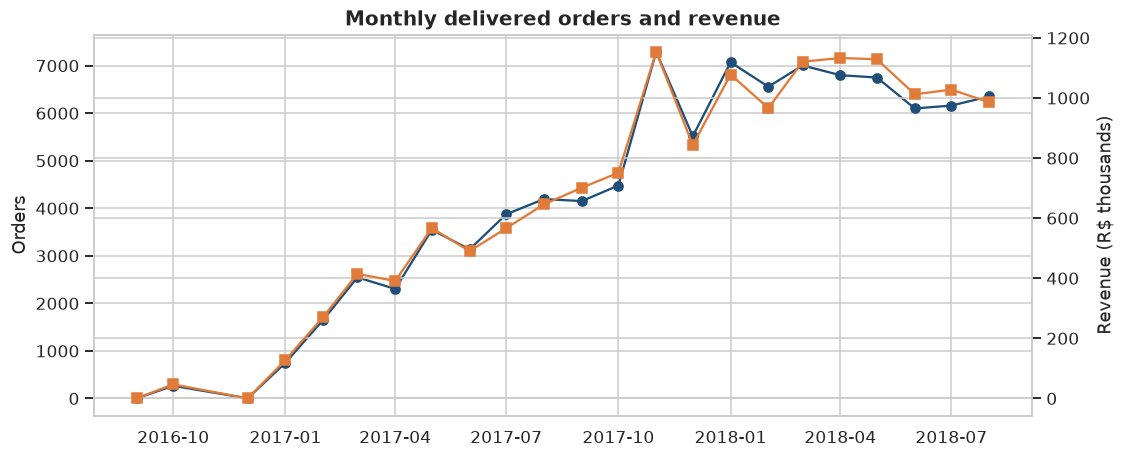

In [3]:
monthly = dl.load_table("analytics.monthly_orders", engine)
monthly["purchase_month"] = pd.to_datetime(monthly["purchase_month"])

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly["purchase_month"], monthly["orders"], marker="o",
        color=PALETTE["primary"], label="Delivered orders")
ax2 = ax.twinx()
ax2.plot(monthly["purchase_month"], monthly["revenue_brl"] / 1000,
         marker="s", color=PALETTE["accent"], label="Revenue (R$ k)")
ax.set_title("Monthly delivered orders and revenue")
ax.set_ylabel("Orders"); ax2.set_ylabel("Revenue (R$ thousands)")
plt.show()

Strong growth through 2017, a peak around **Nov-2017** (Black Friday),
then a high plateau through 2018. The last months are partial (data ends
mid-Oct-2018) — trend claims should exclude the boundary months.

## One-time vs repeat customers

In [4]:
freq = dl.load_table("analytics.customer_purchase_frequency", engine)
freq.head(10)

,order_count,customers,pct_of_customers,revenue_brl,pct_of_revenue
0,1,90557,97.00,"14,555,586.29",94.40
1,2,2573,2.76,"748,811.57",4.86
2,3,181,0.19,"78,333.95",0.51
3,4,28,0.03,"22,086.25",0.14
4,5,9,0.01,"6,607.63",0.04
5,6,5,0.01,"3,455.56",0.02
6,7,3,0.00,"2,840.56",0.02
7,9,1,0.00,"1,172.67",0.01
8,15,1,0.00,879.27,0.01


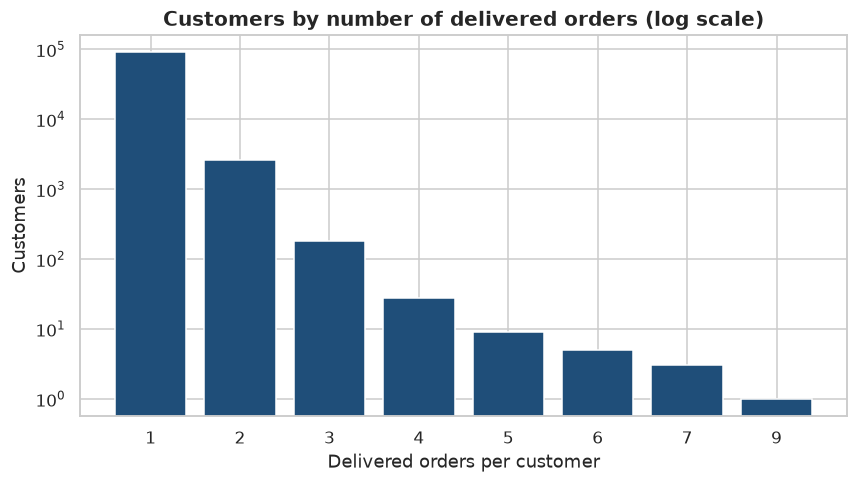

one-time customers: 90,557 of 93,358 (97.0%)


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
top = freq.head(8)
ax.bar(top["order_count"].astype(str), top["customers"],
       color=PALETTE["primary"])
ax.set_yscale("log")
ax.set_title("Customers by number of delivered orders (log scale)")
ax.set_xlabel("Delivered orders per customer"); ax.set_ylabel("Customers")
plt.show()

one_time = freq.loc[freq["order_count"] == 1, "customers"].iloc[0]
total = freq["customers"].sum()
print(f"one-time customers: {one_time:,} of {total:,} "
      f"({one_time/total*100:.1f}%)")

**The central fact of this dataset:** ~97% of customers order exactly
once. Olist is effectively a single-purchase marketplace — which is exactly
why retention analysis matters.

## How long until a second order?

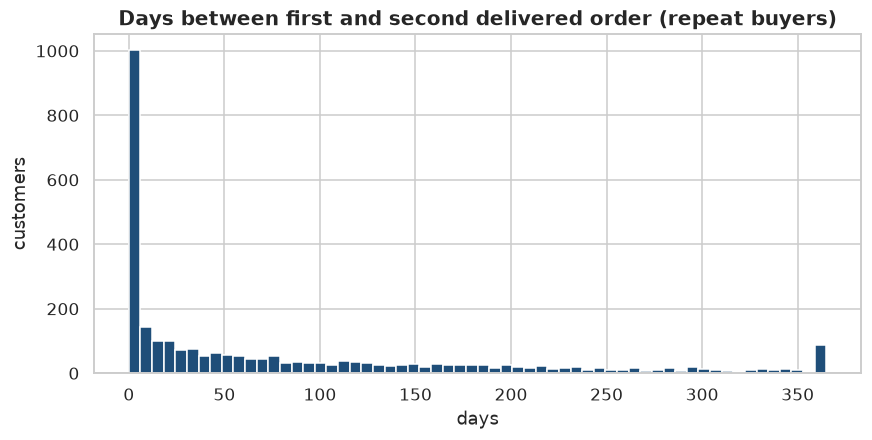

median 29 days | mean 81.2 days


In [6]:
customers = dl.load_table("analytics.customer_metrics", engine)
d2 = customers["days_to_second_order"].dropna()
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(d2.clip(0, 365), bins=60, color=PALETTE["primary"])
ax.set_title("Days between first and second delivered order (repeat buyers)")
ax.set_xlabel("days"); ax.set_ylabel("customers")
plt.show()
print(f"median {d2.median():.0f} days | mean {d2.mean():.1f} days")

## Revenue by category & state

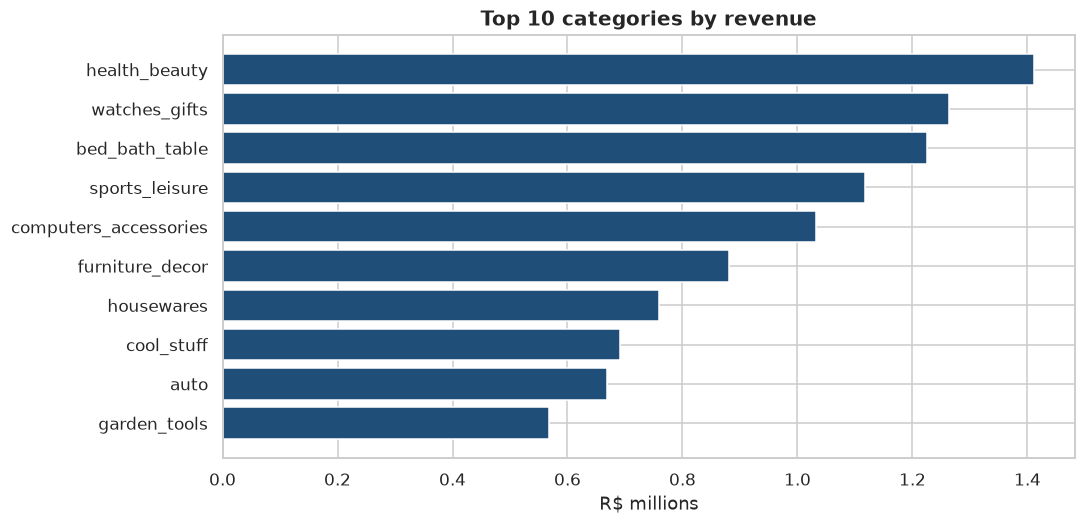

In [7]:
cat = dl.load_table("analytics.revenue_by_category", engine)
fig, ax = plt.subplots(figsize=(10, 5))
top10 = cat.head(10)
ax.barh(top10["product_category"][::-1], top10["revenue_brl"][::-1]/1e6,
        color=PALETTE["primary"])
ax.set_title("Top 10 categories by revenue")
ax.set_xlabel("R$ millions")
plt.show()

In [8]:
st = dl.load_table("analytics.revenue_by_state", engine)
st.head(10)

,customer_state,customers,orders,revenue_brl,pct_revenue,avg_order_value_brl
0,SP,39156,40501,"5,769,703.15",37.42,142.46
1,RJ,11917,12350,"2,055,401.57",13.33,166.43
2,MG,11001,11354,"1,818,891.67",11.80,160.20
3,RS,5168,5345,"861,472.79",5.59,161.17
4,PR,4769,4923,"781,708.80",5.07,158.79
5,SC,3449,3546,"595,127.78",3.86,167.83
6,BA,3158,3256,"591,137.81",3.83,181.55
7,DF,2019,2080,"346,123.35",2.24,166.41
8,GO,1895,1957,"334,212.35",2.17,170.78
9,ES,1928,1995,"317,657.93",2.06,159.23


## Order value distribution

In [9]:
ovd = dl.load_table("analytics.order_value_distribution", engine)
ovd

,p25,p50,p75,p90,p99,mean,max_value
0,61.85,105.28,176.26,305.92,"1,052.39",159.83,"13,664.08"


## Conclusion

* Business grew rapidly to ~R$1M+/month by late 2017, then plateaued.
* **97% of customers buy once** — repeat purchasing is rare in this
  marketplace model.
* Repeat buyers typically return within ~1 month (median 29 days) when
  they do return.
* Revenue is spread across categories; SP state alone is ~37%.
* Median order ~R$105 — meaningful but not huge basket sizes.